In [25]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display
from scipy.io import wavfile

RATE=44100
LA=440
DO = 523.25

2. Synthèse d'un son pur

2.1. Génération d'une sinusoïde

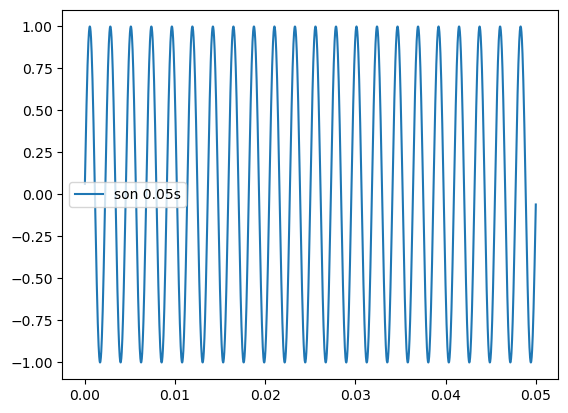

In [24]:
#1. Il faut 44100 échantillons dans notre tableau pour une durée de 1 seconde

#2.équation mathématique qui donne la position de la membrane en fonction du temps $t$ sur l'intervalle $[0, 1]$ pour une fréquence $\phi$
def f(t,phi):
    return np.sin(phi*t*2*np.pi)

#3.
x=np.linspace(0,1,RATE)
son=f(x,440)

plt.plot(x[1:2205],son[1:2205],label="son 0.05s")
plt.legend()
plt.show()

#4.
def display_signal(signal, rate=RATE, title="Signal", width=1):
    return display(Audio(signal,rate=rate))

display_signal(son)

2.2. Généralisation : la fonction `sine()`

In [4]:
def sine(freq, duration=1, amplitude=1.):
    x=np.linspace(0,duration,RATE*duration)
    son=f(x,freq)
    return display_signal(son)

2.3. Glissando (Effet "note qui monte")

In [5]:
def sine_linear(freq1, freq2, duration):
    freq=np.linspace(freq1,freq2,int(RATE*duration))
    phi=2*np.pi*np.cumsum(freq)/RATE
    son=np.sin(phi)
    return display_signal(son)

sine_linear(LA,DO,1)

3. Gestion du volume et de la dynamique ((de)crescendo)

In [6]:
def crescendo_sine(freq, duration, increase=True):
    x=np.linspace(0,duration,RATE*duration)
    if increase==True:
        y=np.linspace(0,1,RATE*duration)
    else:
        y=np.linspace(1,0,RATE*duration)
    son=np.multiply(f(x,freq),y)
    return display_signal(son)

crescendo_sine(LA,2,increase=True)


4. Concaténation de sons

In [7]:
x=np.linspace(0,2,RATE*2)
la=f(x[0:RATE],LA)
do=f(x[RATE:RATE*2],DO)
sonCon=np.concatenate((la,do))
display_signal(sonCon)

5. Formats de données audio (mise à l'échelle)

In [10]:
def float_to_int16(as_float):
    tab=as_float*32767
    return tab.astype(np.int16)

6. Les fréquences des notes de la gamme

In [26]:
#Ex.1
ratio=np.array([2**(k/12) for k in range (13)])

In [29]:
#Ex.2
def freq_from_name(name):
    N=["LA","LA#","SI","DO","DO#","RE","RE#","MI","FA","FA#","SOL","SOL#"] #on peut egalement commencer la gamme par do
    for i in range (len(N)):
        if name==N[i]:
            return 440*2**(i/12) #dans le cas ou la gamme commence par do, on return 440*2**((i-9)/12)
        
#Ex.3
freq_from_name('DO') == 440*2**(3/12)

True

7. Les accords : Superposition de sons 

En additionnant des tableaux de notes (de même dimension), on obtient des accords.

8. Sauvegarde et chargement de fichiers `.wav`

In [30]:
#1.
x=np.linspace(0,2,RATE*2)
la=f(x,LA)
do=f(x,DO)
la_do=np.add(la,do)/2 #je divise par 2 pour ne pas avoir de problème avec la fonction float_to_int16
display_signal(la_do)
la_do=float_to_int16(la_do)
wavfile.write('sample.wav',RATE,la_do)

In [31]:
#2.
rate,restored=wavfile.read("sample.wav")

In [32]:
#3.
display_signal(restored)

9. Analyse d'un son réel

44100
405891
9.203877551020408


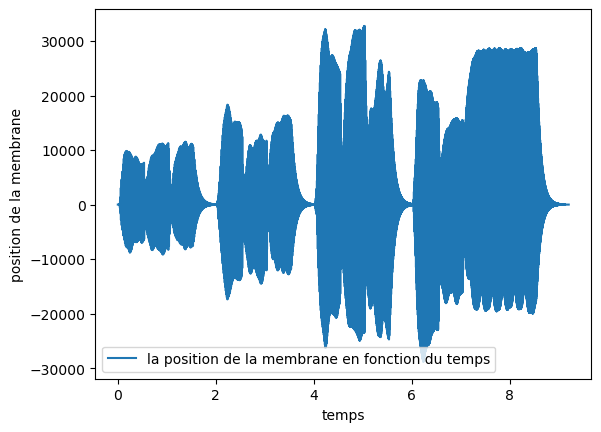

In [38]:
#1.
samplerate, data=wavfile.read('sounds-cellocopie.wav')

#2.
display_signal(data)

#3.
print(samplerate)

#4.
print(data.shape[0])

#5.
duree=data.shape[0]/samplerate
print(duree)

#6.
x=np.linspace(0,duree,data.shape[0])
plt.plot(x,data,label="la position de la membrane en fonction du temps")
plt.xlabel('temps')
plt.ylabel('position de la membrane')
plt.legend()
plt.show()


10. Ajout d'un effet d'écho

In [17]:
delay = 2  # en secondes
main_ratio, delayed_ratio = 0.7, 0.3

#ex v1

offset=RATE*delay
echo=[0 for i in range (data.shape[0])]
echo[offset:]=delayed_ratio*data[:-offset]

signal_echo=np.add(main_ratio*data,echo)
display_signal(signal_echo)


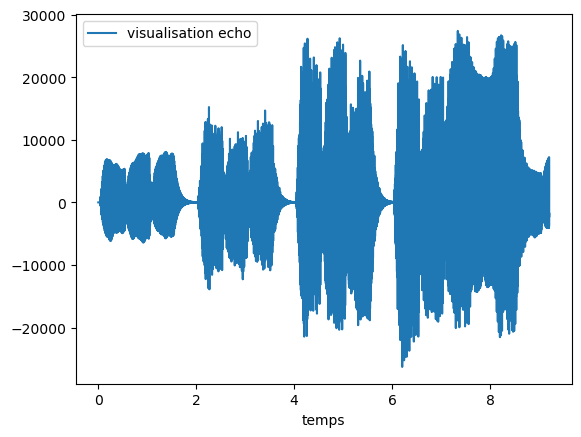

In [66]:
#visualisation du résultat
x=np.linspace(0,signal_echo.shape[0]/RATE,signal_echo.shape[0])
plt.plot(x,signal_echo,label='visualisation echo')
plt.xlabel('temps')
plt.legend()
plt.show()

In [18]:
#ex v2

echo2=[0 for i in range (data.shape[0]+offset)]
echo2[offset:]+=delayed_ratio*data
echo2[:data.shape[0]]+=data*main_ratio
display_signal(echo2)


11. Transposition

11.1. Transposer d'une octave

On peut produire un son à l'octave en lisant l'audio deux fois plus vite (la fréquence est alors doublée).

In [19]:
display_signal(data,rate=2*RATE)

11.2. Transposer d'une quinte

In [20]:
#essai
display_signal(data,rate=3/2*RATE)

In [39]:
#1.
data3=float_to_int16(np.array([0 for k in range (int(2/3*data.shape[0]))]))

#2. 
data3[0::2]=data[0::3]

#3.
data3[1:-1:2]=(data[0:-3:3].astype(np.int32)+data[3::3].astype(np.int32))/2
display_signal(data3)